In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tornado_df = pd.read_csv("../../../data/disaster_data/tornados/major_tornadoes_2000_2026.csv")

# Parse tornado dates
tornado_df["start_date"] = pd.to_datetime(
    tornado_df["start_date"],
    format="%d-%b-%y %H:%M:%S",
    errors="coerce"
)

tornado_df["end_date"] = pd.to_datetime(
    tornado_df["end_date"],
    format="%d-%b-%y %H:%M:%S",
    errors="coerce"
)

numeric_cols = [
    "total_damage_usd",
    "total_deaths",
    "injuries",
    "path_length_miles",
    "path_width_yards"
]

for col in numeric_cols:
    tornado_df[col] = pd.to_numeric(
        tornado_df[col], errors="coerce"
    )

tornado_df = tornado_df.drop_duplicates(
    subset=["tornado_id"]
)

print("Total tornado records:", len(tornado_df))
display(tornado_df.head())


Total tornado records: 241


,tornado_id,episode_id,start_date,end_date,state,county,location,tornado_magnitude,path_length_miles,path_width_yards,total_damage_usd,total_deaths,injuries,start_lat,start_lon,event_description
0,296617,49972,2011-05-22 16:40:00,2011-05-22 17:00:00,MISSOURI,JASPER,CENTRAL CITY,EF5,8.80,1600.0,2.800000e+09,161,1150,37.0560,-94.5701,National Weather Service survey teams rated th...
1,451572,74673,2013-05-20 14:04:00,2013-05-20 14:35:00,OKLAHOMA,CLEVELAND,MOORE,EF5,12.00,1900.0,2.000000e+09,24,207,35.3030,-97.6050,The violent Newcastle-Moore tornado moved into...
2,1262207,202193,2025-05-16 13:41:00,2025-05-16 13:48:00,MISSOURI,ST. LOUIS (C),TOWER GROVE,EF3,6.61,3168.0,1.600000e+09,4,38,38.6446,-90.3039,The tornado was its widest and strongest in St...
3,856409,142648,2019-10-20 19:58:00,2019-10-20 20:30:00,TEXAS,DALLAS,GRIBBLE,EF3,15.76,1300.0,1.550000e+09,0,0,32.8685,-96.9149,"The tornado formed in northwest Dallas, near S..."
4,314662,50455,2011-04-27 15:48:00,2011-04-27 16:35:00,ALABAMA,TUSCALOOSA,RALPH,EF4,41.79,1760.0,1.500000e+09,52,800,33.0606,-87.8315,This tornado initially touched down in rural n...


In [2]:

N = 10

top_tornadoes = (
    tornado_df
    .sort_values("total_damage_usd", ascending=False)
    .head(N)
    .copy()
)

top_tornadoes["damage_millions"] = (
    top_tornadoes["total_damage_usd"] / 1e6
)

display(
    top_tornadoes[
        ["tornado_id", "start_date", "state",
         "tornado_magnitude", "damage_millions"]
    ]
)


,tornado_id,start_date,state,tornado_magnitude,damage_millions
0,296617,2011-05-22 16:40:00,MISSOURI,EF5,2800.0
1,451572,2013-05-20 14:04:00,OKLAHOMA,EF5,2000.0
2,1262207,2025-05-16 13:41:00,MISSOURI,EF3,1600.0
3,856409,2019-10-20 19:58:00,TEXAS,EF3,1550.0
4,314662,2011-04-27 15:48:00,ALABAMA,EF4,1500.0
5,882999,2020-03-03 00:32:00,TENNESSEE,EF3,1090.0
6,301902,2011-04-27 15:17:00,ALABAMA,EF4,1000.0
7,483775,2013-11-17 10:59:00,ILLINOIS,EF4,910.0
8,314663,2011-04-27 16:35:00,ALABAMA,EF4,700.0
9,816403,2019-05-27 21:41:00,OHIO,EF4,500.0


In [4]:


market_df = pd.read_csv(
    "../../../data/stock_data/market_raw.csv"
)


market_df["Date"] = pd.to_datetime(market_df["Date"])

market_df = (
    market_df
    .sort_values("Date")
    .drop_duplicates(subset=["Date"])
    .reset_index(drop=True)
)

sectors = ["SPY", "XLE", "XLU", "XLF", "XLI"]
windows = [1, 5, 14]

top_tornadoes = pd.merge_asof(
    top_tornadoes.sort_values("start_date"),
    market_df[["Date"]].sort_values("Date"),
    left_on="start_date",
    right_on="Date",
    direction="forward"
)

top_tornadoes = top_tornadoes.rename(
    columns={"Date": "event_trading_date"}
)

display(
    top_tornadoes[
        ["tornado_id", "start_date",
         "event_trading_date"]
    ]
)


,tornado_id,start_date,event_trading_date
0,301902,2011-04-27 15:17:00,2011-04-28
1,314662,2011-04-27 15:48:00,2011-04-28
2,314663,2011-04-27 16:35:00,2011-04-28
3,296617,2011-05-22 16:40:00,2011-05-23
4,451572,2013-05-20 14:04:00,2013-05-21
5,483775,2013-11-17 10:59:00,2013-11-18
6,816403,2019-05-27 21:41:00,2019-05-28
7,856409,2019-10-20 19:58:00,2019-10-21
8,882999,2020-03-03 00:32:00,2020-03-04
9,1262207,2025-05-16 13:41:00,2025-05-19


In [5]:

results = []

market_dates = pd.Index(market_df["Date"])

for _, tornado in top_tornadoes.iterrows():
    event_date = tornado["event_trading_date"]

    if pd.isna(event_date):
        continue

    idx = market_dates.get_loc(event_date)

    for sector in sectors:
        close_col = f"{sector}_Close"

        for window in windows:
            future_idx = idx + window

            if future_idx >= len(market_df):
                continue

            p0 = market_df.loc[idx, close_col]
            p1 = market_df.loc[future_idx, close_col]

            if pd.isna(p0) or pd.isna(p1) or p0 <= 0:
                continue

            pct_return = (p1 / p0 - 1) * 100

            results.append({
                "tornado_id": tornado["tornado_id"],
                "state": tornado["state"],
                "magnitude": tornado["tornado_magnitude"],
                "start_date": tornado["start_date"],
                "damage_usd": tornado["total_damage_usd"],
                "sector": sector,
                "window": window,
                "return_pct": pct_return
            })

tornado_returns = pd.DataFrame(results)

display(tornado_returns.head(15))


,tornado_id,state,magnitude,start_date,damage_usd,sector,window,return_pct
0,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,SPY,1,0.235116
1,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,SPY,5,-1.836754
2,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,SPY,14,-1.285698
3,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,XLE,1,1.487988
4,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,XLE,5,-6.090797
5,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,XLE,14,-5.788121
6,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,XLU,1,0.211517
7,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,XLU,5,0.030224
8,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,XLU,14,3.022037
9,301902,ALABAMA,EF4,2011-04-27 15:17:00,1.000000e+09,XLF,1,-0.182869


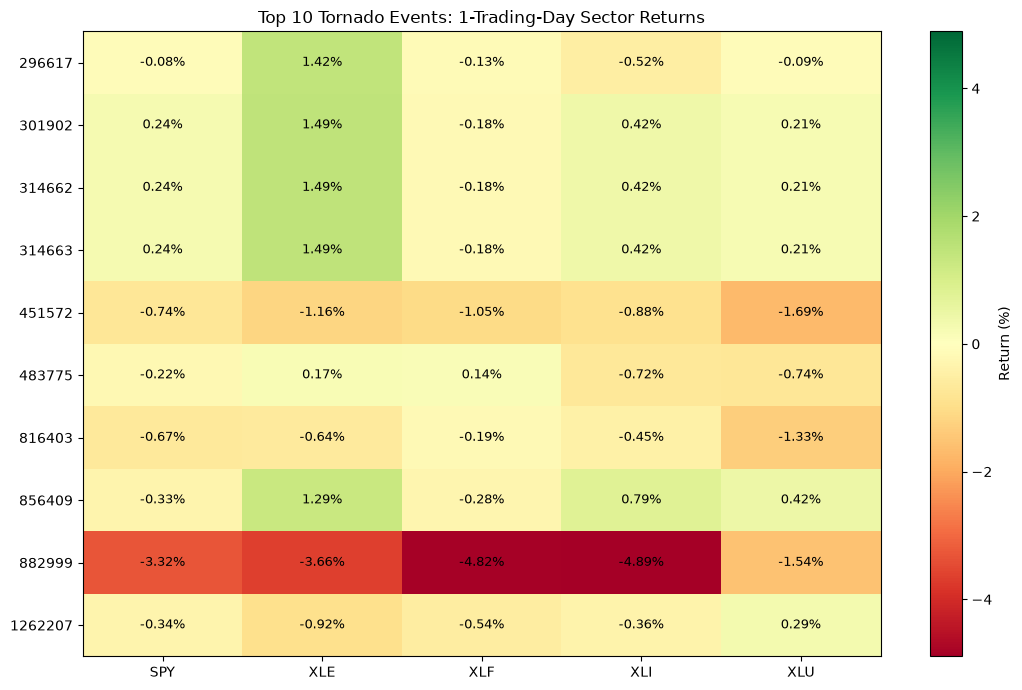

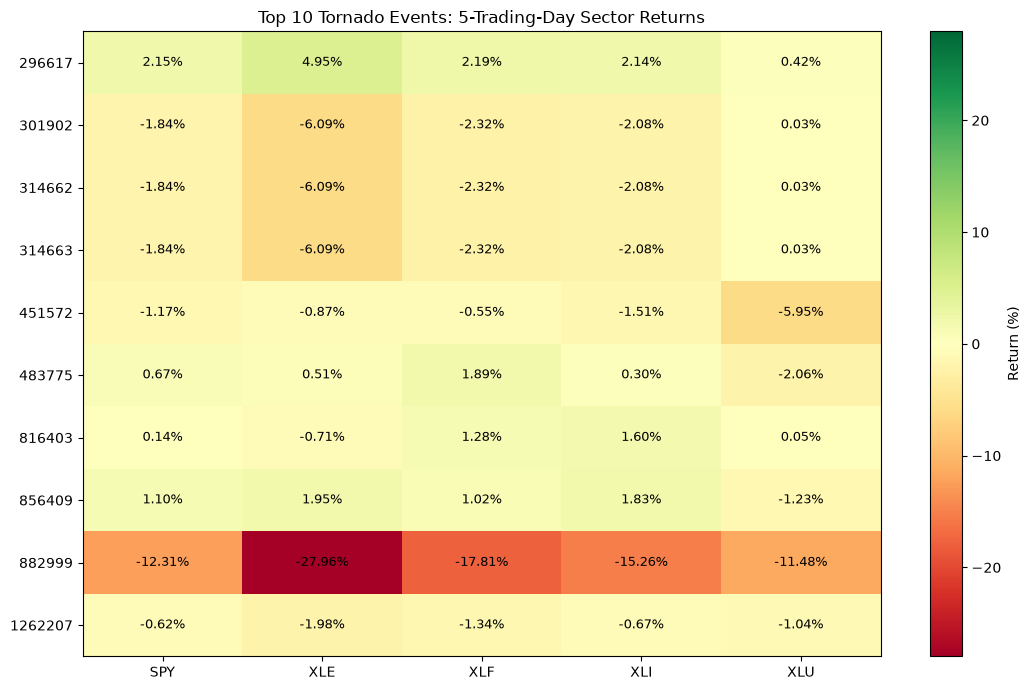

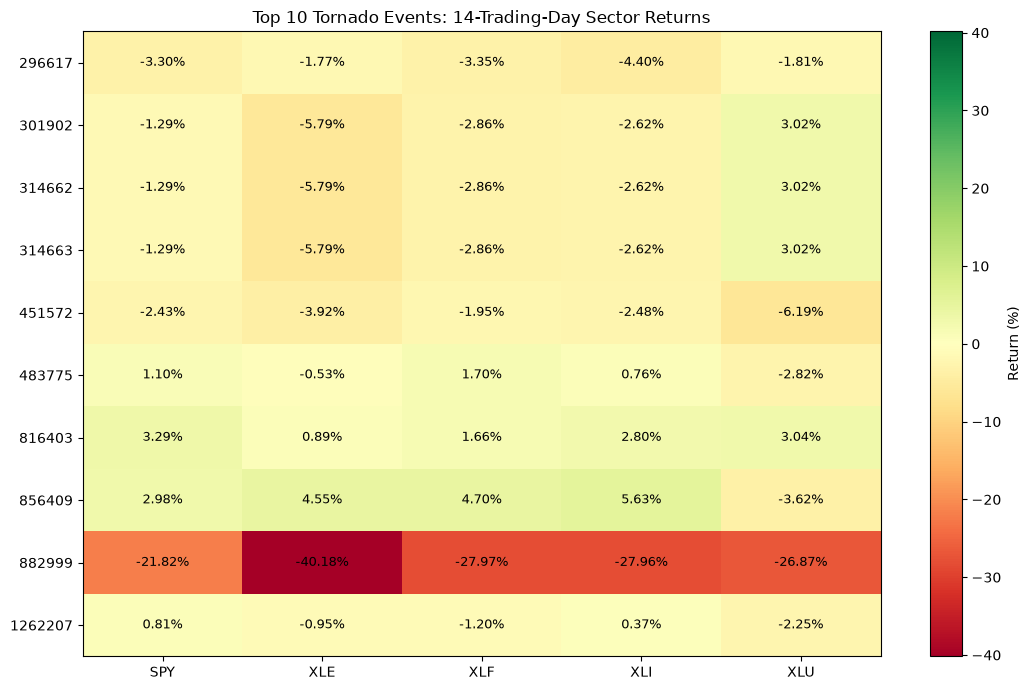

In [6]:

for window in windows:
    heatmap = (
        tornado_returns[
            tornado_returns["window"] == window
        ]
        .pivot(
            index="tornado_id",
            columns="sector",
            values="return_pct"
        )
    )

    fig, ax = plt.subplots(figsize=(11, 7))

    limit = max(
        np.nanmax(np.abs(heatmap.to_numpy())),
        0.01
    )

    im = ax.imshow(
        heatmap,
        cmap="RdYlGn",
        vmin=-limit,
        vmax=limit,
        aspect="auto"
    )

    ax.set_xticks(range(len(heatmap.columns)))
    ax.set_xticklabels(heatmap.columns)

    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)

    for i in range(len(heatmap.index)):
        for j in range(len(heatmap.columns)):
            value = heatmap.iloc[i, j]

            if pd.notna(value):
                ax.text(
                    j, i, f"{value:.2f}%",
                    ha="center",
                    va="center",
                    fontsize=9
                )

    ax.set_title(
        f"Top {N} Tornado Events: "
        f"{window}-Trading-Day Sector Returns"
    )

    plt.colorbar(im, ax=ax, label="Return (%)")
    plt.tight_layout()
    plt.show()


In [7]:

# Use all tornado records
all_tornadoes = tornado_df.copy()

# Match using calendar dates
all_tornadoes["event_date"] = (
    all_tornadoes["start_date"].dt.normalize()
)

market_df["Date"] = (
    pd.to_datetime(market_df["Date"]).dt.normalize()
)

market_df = (
    market_df.sort_values("Date")
    .drop_duplicates("Date")
    .reset_index(drop=True)
)

all_tornadoes = pd.merge_asof(
    all_tornadoes.sort_values("event_date"),
    market_df[["Date"]].sort_values("Date"),
    left_on="event_date",
    right_on="Date",
    direction="forward"
)

all_tornadoes = all_tornadoes.rename(
    columns={"Date": "event_trading_date"}
)

# Calculate returns
results = []
market_dates = pd.Index(market_df["Date"])

for _, tornado in all_tornadoes.iterrows():
    event_date = tornado["event_trading_date"]

    if pd.isna(event_date):
        continue

    idx = market_dates.get_loc(event_date)

    for sector in sectors:
        close_col = f"{sector}_Close"

        for window in windows:
            future_idx = idx + window

            if future_idx >= len(market_df):
                continue

            p0 = market_df.loc[idx, close_col]
            p1 = market_df.loc[future_idx, close_col]

            if pd.isna(p0) or pd.isna(p1) or p0 <= 0:
                continue

            results.append({
                "tornado_id": tornado["tornado_id"],
                "sector": sector,
                "window": window,
                "return_pct": (p1 / p0 - 1) * 100
            })

all_tornado_returns = pd.DataFrame(results)

display(all_tornado_returns.head())


,tornado_id,sector,window,return_pct
0,5132156,SPY,1,1.131306
1,5132156,SPY,5,-3.248140
2,5132156,SPY,14,0.179257
3,5132156,XLE,1,4.186631
4,5132156,XLE,5,0.598088


In [8]:

# Extract numerical magnitude from F/EF ratings
all_tornadoes["magnitude_num"] = pd.to_numeric(
    all_tornadoes["tornado_magnitude"]
    .astype(str)
    .str.extract(r"(?:EF|F)([0-5])", expand=False),
    errors="coerce"
)

all_tornadoes["strong_tornado"] = (
    all_tornadoes["magnitude_num"] >= 3
)

all_tornadoes["violent_tornado"] = (
    all_tornadoes["magnitude_num"] >= 4
)

all_tornadoes["high_damage"] = (
    all_tornadoes["total_damage_usd"] >= 100_000_000
)

all_tornadoes["long_path"] = (
    all_tornadoes["path_length_miles"] >= 20
)

all_tornadoes["wide_tornado"] = (
    all_tornadoes["path_width_yards"] >= 1000
)

all_tornadoes["fatal_tornado"] = (
    all_tornadoes["total_deaths"] > 0
)

all_tornadoes["high_injuries"] = (
    all_tornadoes["injuries"] >= 20
)


In [9]:

returns_5d = (
    all_tornado_returns[
        all_tornado_returns["window"] == 5
    ]
    .pivot(
        index="tornado_id",
        columns="sector",
        values="return_pct"
    )
)

returns_5d.columns = [
    f"{col}_return_5d"
    for col in returns_5d.columns
]

fp_df = all_tornadoes.merge(
    returns_5d,
    on="tornado_id",
    how="inner"
)

return_cols = [
    f"{sector}_return_5d" for sector in sectors
]

fp_df = fp_df.dropna(subset=return_cols)

for sector in sectors:
    fp_df[f"{sector}_up"] = (
        fp_df[f"{sector}_return_5d"] > 0
    )

    fp_df[f"{sector}_down"] = (
        fp_df[f"{sector}_return_5d"] < 0
    )

display(fp_df.head())


,tornado_id,episode_id,start_date,end_date,state,county,location,tornado_magnitude,path_length_miles,path_width_yards,...,SPY_up,SPY_down,XLE_up,XLE_down,XLU_up,XLU_down,XLF_up,XLF_down,XLI_up,XLI_down
0,5132156,1091370,2000-02-13 23:42:00,2000-02-14 00:03:00,GEORGIA,MITCHELL,CAMILLA,F3,9.2,300.0,...,False,True,True,False,False,True,False,True,True,False
1,5163249,1100104,2000-07-25 16:57:00,2000-07-25 17:25:00,MINNESOTA,YELLOW MEDICINE,GRANITE FALLS,F4,9.0,167.0,...,False,True,True,False,True,False,False,False,False,True
2,5175230,1103177,2000-09-20 18:18:00,2000-09-20 18:26:00,OHIO,GREENE,XENIA,F4,9.0,500.0,...,False,True,True,False,True,False,True,False,True,False
3,5166971,1104971,2000-12-16 12:54:00,2000-12-16 13:12:00,ALABAMA,TUSCALOOSA,HULL,F4,18.0,750.0,...,False,True,True,False,False,True,True,False,False,True
4,5236229,1111956,2001-04-21 20:15:00,2001-04-21 20:35:00,KANSAS,BARTON,HOISINGTON,F4,5.0,660.0,...,True,False,True,False,True,False,True,False,True,False


In [10]:

tornado_features = [
    "strong_tornado",
    "violent_tornado",
    "high_damage",
    "long_path",
    "wide_tornado",
    "fatal_tornado",
    "high_injuries"
]

market_features = [
    f"{sector}_{direction}"
    for sector in sectors
    for direction in ["up", "down"]
]

transaction_cols = tornado_features + market_features

transactions = (
    fp_df[transaction_cols]
    .fillna(False)
    .astype(bool)
)

display(transactions.head())


,strong_tornado,violent_tornado,high_damage,long_path,wide_tornado,fatal_tornado,high_injuries,SPY_up,SPY_down,XLE_up,XLE_down,XLU_up,XLU_down,XLF_up,XLF_down,XLI_up,XLI_down
0,True,False,False,False,False,True,True,False,True,True,False,False,True,False,True,True,False
1,True,True,False,False,False,True,False,False,True,True,False,True,False,False,False,False,True
2,True,True,False,False,False,True,True,False,True,True,False,True,False,True,False,True,False
3,True,True,False,False,False,True,True,False,True,True,False,False,True,True,False,False,True
4,True,True,False,False,False,True,True,True,False,True,False,True,False,True,False,True,False


In [11]:

# Install if needed:
# %pip install mlxtend

from mlxtend.frequent_patterns import (
    fpgrowth,
    association_rules
)

frequent_itemsets = fpgrowth(
    transactions,
    min_support=0.15,
    use_colnames=True
)

frequent_itemsets = frequent_itemsets.sort_values(
    "support",
    ascending=False
)

display(frequent_itemsets.head(20))


,support,itemsets
0,0.970833,frozenset({strong_tornado})
8,0.829167,frozenset({violent_tornado})
387,0.829167,"frozenset({violent_tornado, strong_tornado})"
1,0.612500,frozenset({XLF_down})
9,0.608333,frozenset({XLU_up})
17,0.600000,"frozenset({XLF_down, strong_tornado})"
388,0.591667,"frozenset({XLU_up, strong_tornado})"
2,0.583333,frozenset({fatal_tornado})
20,0.575000,"frozenset({fatal_tornado, strong_tornado})"
13,0.529167,frozenset({XLE_down})


In [12]:

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.6
)

rules = rules[
    rules["antecedents"].apply(
        lambda x: (
            len(x) > 0
            and x.issubset(set(tornado_features))
        )
    )
    &
    rules["consequents"].apply(
        lambda x: (
            len(x) == 1
            and x.issubset(set(market_features))
        )
    )
]

rules = rules[rules["lift"] > 1.2]

rules = rules.sort_values(
    ["lift", "confidence"],
    ascending=False
)

display(
    rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(20)
)


,antecedents,consequents,support,confidence,lift
1925,"frozenset({fatal_tornado, violent_tornado, wid...",frozenset({XLF_down}),0.225000,0.794118,1.296519
1932,"frozenset({fatal_tornado, violent_tornado, wid...",frozenset({XLF_down}),0.225000,0.794118,1.296519
937,"frozenset({violent_tornado, wide_tornado, stro...",frozenset({XLE_down}),0.266667,0.680851,1.286648
959,"frozenset({violent_tornado, wide_tornado})",frozenset({XLE_down}),0.266667,0.680851,1.286648
3409,"frozenset({fatal_tornado, violent_tornado, wid...",frozenset({XLE_down}),0.191667,0.676471,1.278370
3414,"frozenset({fatal_tornado, violent_tornado, wid...",frozenset({XLE_down}),0.191667,0.676471,1.278370
1139,"frozenset({fatal_tornado, wide_tornado})",frozenset({XLF_down}),0.254167,0.782051,1.276818
1143,"frozenset({fatal_tornado, wide_tornado, strong...",frozenset({XLF_down}),0.254167,0.782051,1.276818
2036,"frozenset({fatal_tornado, wide_tornado})",frozenset({XLE_down}),0.216667,0.666667,1.259843
2147,"frozenset({fatal_tornado, wide_tornado, strong...",frozenset({XLE_down}),0.216667,0.666667,1.259843


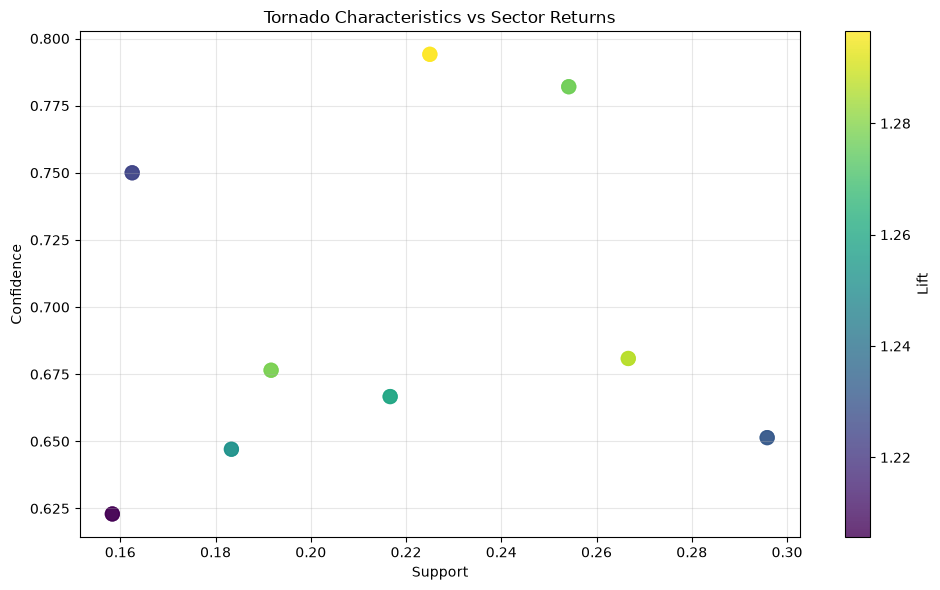

In [13]:

plot_rules = rules.copy()

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    plot_rules["support"],
    plot_rules["confidence"],
    c=plot_rules["lift"],
    cmap="viridis",
    s=100,
    alpha=0.8
)

plt.colorbar(scatter, label="Lift")

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Tornado Characteristics vs Sector Returns")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


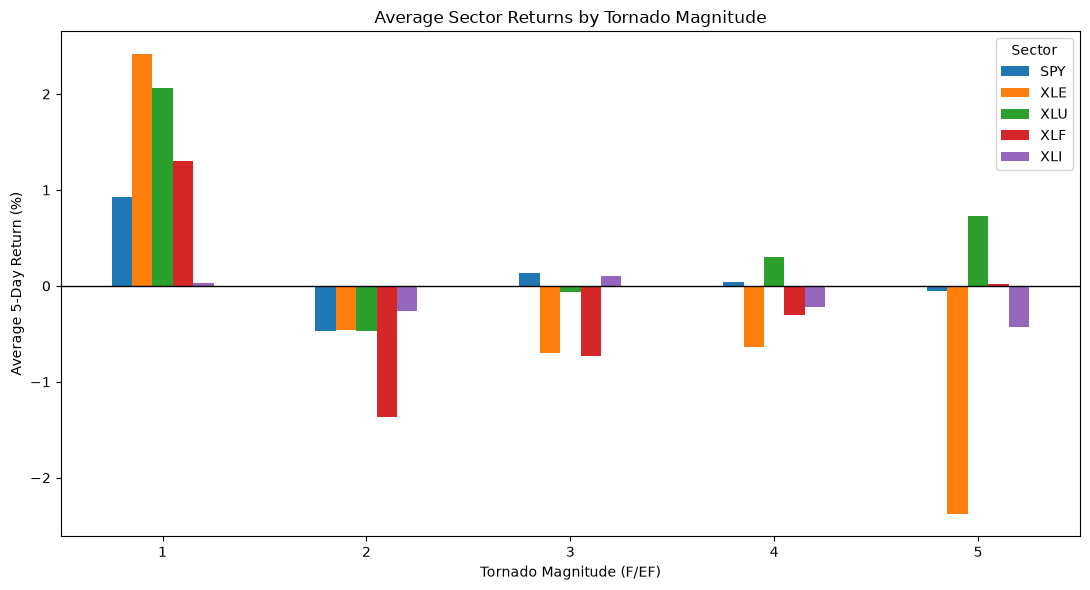

In [14]:

magnitude_returns = fp_df.groupby(
    "magnitude_num"
)[return_cols].mean()

magnitude_returns.columns = sectors

ax = magnitude_returns.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Tornado Magnitude (F/EF)")
ax.set_ylabel("Average 5-Day Return (%)")
ax.set_title(
    "Average Sector Returns by Tornado Magnitude"
)

plt.xticks(rotation=0)
plt.legend(title="Sector")
plt.tight_layout()
plt.show()
